# LGD de recuperación: flujos, descuento y recuperaciones incompletas

**Pregunta:** ¿Qué parte de un préstamo en incumplimiento se pierde una vez descontadas sus recuperaciones, y qué tan lejos de esa medida de recuperación está el indicador de castigos que el caso C08 construye con los préstamos a pequeñas empresas SBA 7(a)?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los notebooks 01 y 02 del tema 01 (el motor y un artefacto)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- escribir la LGD realizada de un préstamo en incumplimiento como uno menos las recuperaciones netas descontadas sobre la exposición al incumplimiento, y calcularla a mano y con `workout_lgd`;
- decir qué hace la tasa de descuento a una LGD, y construir la tasa al estilo europeo con `eba_discount_rate`;
- marcar una LGD bajo 0 o sobre 1 con `range_flag`, y explicar por qué se conserva y nunca se recorta;
- decir por qué dejar fuera las recuperaciones abiertas sesga la LGD a la baja, y tratarlas de forma explícita con `resolve_incomplete` y `closed_before`;
- leer la LGD del caso C08, un indicador sustituto de castigos sobre los préstamos a pequeñas empresas SBA 7(a), y decir con exactitud en qué se diferencia de una LGD de recuperación.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir sus versiones, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import workout

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Un artefacto versionado, `data/derived/C08/dc-2007-08.json`, la variante del caso C08 para los incumplimientos de 2007 y 2008. C08 se construye sobre el archivo público de préstamos SBA 7(a) (préstamos a pequeñas empresas, una fuente con espejo permitido), porque los campos de pérdida de Freddie Mac quedan derivados y fuera de línea en este producto. El archivo **no tiene flujos de recuperación**: registra el monto castigado y el monto aprobado. Por eso la LGD de C08 es un *indicador sustituto*, y el artefacto lo dice en `outputs.lgd_proxy`.

Por eso este notebook tiene dos mitades. La primera enseña la LGD de recuperación sobre un ejemplo trabajado pequeño, cuyos flujos están escritos en el notebook (cuatro préstamos inventados, rotulados como tales), porque las funciones `workout` del motor necesitan flujos. La segunda lee el artefacto C08 versionado y muestra qué es un indicador sustituto de castigos, qué oculta y cómo lo marca el motor. El artefacto fue horneado con un motor anterior al instalado aquí, así que la celda siguiente imprime la versión con que se horneó.

In [2]:
# Abrir el artefacto versionado del caso C08 e imprimir la versión del motor que lo horneó
ROOT = Path("../../..").resolve()
c08 = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2007-08.json").read_text(encoding="utf-8"))
out = c08["outputs"]
print("caso:", c08["case_id"], "| variante:", c08["variant_id"], "|", out["cohort"]["label"]["es"])
print("horneado con riskvalidation:", c08["provenance"]["riskvalidation_version"])
print("instalado:", rv.__version__)

caso: C08 | variante: dc-2007-08 | Incumplimientos 2007-08
horneado con riskvalidation: 1.0.1
instalado: 1.0.1


## Método

### Paso 1: la LGD realizada de un préstamo

Para un préstamo en incumplimiento $i$ con exposición al incumplimiento $EAD_i$, el módulo `workout` del motor calcula

$$LGD_i = 1 - \frac{\sum_t (R_t - C_t - A_t)\,(1 + r_i)^{-t}}{EAD_i}$$

donde $R_t$ es una recuperación recibida en el momento $t$ (en años desde la fecha de incumplimiento), $C_t$ los costos directos e indirectos pagados en $t$, $A_t$ un giro adicional posterior al incumplimiento y $r_i$ la tasa de descuento. La suma es el valor presente, a la fecha de incumplimiento, de todo lo que el banco recuperó neto de lo que pagó; uno menos su parte de la exposición es la parte perdida. (Fuente: el docstring de `riskvalidation.lgd_ead.workout` en la versión 0.8.1; la regla de la tasa de descuento se describe en el paso 2.)

Abajo, cuatro préstamos inventados. Cada fila de los arreglos es un préstamo y cada columna una fecha de flujo. La primera celda los escribe y luego calcula el préstamo A **a mano**, un flujo a la vez, para que cada intermedio quede a la vista.

In [3]:
# Cuatro préstamos inventados en incumplimiento (A a D), y el préstamo A a mano con una tasa de 8%, un flujo a la vez
loans = ["A", "B", "C", "D"]
ead = np.array([100_000.0, 50_000.0, 80_000.0, 20_000.0])
times = np.array([[0.5, 1.0, 2.0], [0.25, 1.0, 1.5], [1.0, 2.0, 3.0], [0.5, 1.0, 1.5]])
recoveries = np.array([[30_000, 40_000, 20_000], [10_000, 15_000, 10_000],
                       [5_000, 8_000, 2_000], [14_000, 9_000, 4_000]], dtype=float)
costs = np.array([[2_000, 2_000, 1_000], [3_000, 1_000, 500],
                  [9_000, 7_000, 6_000], [500, 200, 100]], dtype=float)
drawings = np.zeros_like(recoveries)

rate = 0.08
net = recoveries[0] - costs[0] - drawings[0]
factor = (1 + rate) ** (-times[0])
present = net * factor
fmt = "flujo {}: t={:<4} neto={:>8,.0f} factor={:.4f} valor presente={:>9,.2f}"
for k in range(3):
    print(fmt.format(k + 1, times[0, k], net[k], factor[k], present[k]))
print(f"suma de valores presentes: {present.sum():,.2f} | EAD: {ead[0]:,.0f}")
print(f"LGD = 1 - {present.sum():,.2f} / {ead[0]:,.0f} = {1 - present.sum() / ead[0]:.4f}")

flujo 1: t=0.5  neto=  28,000 factor=0.9623 valor presente=26,943.01
flujo 2: t=1.0  neto=  38,000 factor=0.9259 valor presente=35,185.19
flujo 3: t=2.0  neto=  19,000 factor=0.8573 valor presente=16,289.44
suma de valores presentes: 78,417.64 | EAD: 100,000
LGD = 1 - 78,417.64 / 100,000 = 0.2158


El mismo número sale de `workout_lgd`, que hace toda la tabla de una vez y rechaza la entrada mala (una EAD no positiva, un flujo negativo, un tiempo en o antes de la fecha de incumplimiento). La celda siguiente la llama para los cuatro préstamos con la misma tasa y compara el préstamo A con el cálculo a mano.

In [4]:
# Correr workout_lgd del motor sobre los cuatro préstamos con la misma tasa
lgd = workout.workout_lgd(ead, times, recoveries, costs, drawings, rate)
for name, value in zip(loans, lgd):
    print(f"préstamo {name}: LGD = {value:.4f}")
print(f"préstamo A a mano: {1 - present.sum() / ead[0]:.4f}")

préstamo A: LGD = 0.2158
préstamo B: LGD = 0.4341
préstamo C: LGD = 1.0753
préstamo D: LGD = -0.2307
préstamo A a mano: 0.2158


### Paso 2: la tasa de descuento

La tasa importa: una recuperación a dos años vale menos a la fecha de incumplimiento que una que llega el próximo mes. La convención europea es una tasa interbancaria a la fecha de incumplimiento más un recargo; `eba_discount_rate(interbank_rate, add_on=0.05)` devuelve esa suma. El número de párrafo de la guía de la EBA detrás del recargo de 5% está marcado NO VERIFICADO en el propio motor, así que este notebook enuncia la convención y no cita un párrafo. Quien llama puede pasar cualquier otra tasa a `workout_lgd`.

La celda siguiente construye la tasa para una interbancaria de 3% y recalcula las cuatro LGD en una grilla de tasas de 0% a 15%. La dirección esperada: una tasa más alta reduce el valor presente de las recuperaciones netas y sube la LGD de un préstamo con flujos netos positivos; el préstamo C, de flujos netos negativos, es la excepción.

Tasa al estilo europeo (3% interbancaria + 5% de recargo): 0.08
tasa 0.00: A  0.1500  B  0.3900  C  1.0875  D -0.3100
tasa 0.08: A  0.2158  B  0.4341  C  1.0753  D -0.2307
tasa 0.12: A  0.2447  B  0.4536  C  1.0703  D -0.1952


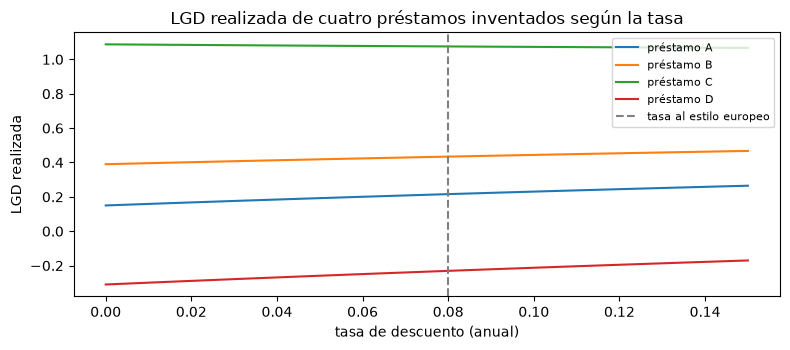

In [5]:
# Construir la tasa al estilo europeo, recalcular las cuatro LGD en una grilla de tasas y dibujarlas
eu_rate = workout.eba_discount_rate(0.03)
print(f"Tasa al estilo europeo (3% interbancaria + 5% de recargo): {eu_rate:.2f}")
grid = np.linspace(0.0, 0.15, 31)
curves = np.array([workout.workout_lgd(ead, times, recoveries, costs, drawings, r) for r in grid])
for r in (0.0, eu_rate, 0.12):
    row = workout.workout_lgd(ead, times, recoveries, costs, drawings, r)
    print(f"tasa {r:.2f}: " + "  ".join(f"{n} {v:7.4f}" for n, v in zip(loans, row)))

fig, ax = plt.subplots(figsize=(8, 3.6))
for j, name in enumerate(loans):
    ax.plot(grid, curves[:, j], label=f"préstamo {name}")
ax.axvline(eu_rate, color="grey", linestyle="--", label="tasa al estilo europeo")
ax.set_xlabel("tasa de descuento (anual)")
ax.set_ylabel("LGD realizada")
ax.set_title("LGD realizada de cuatro préstamos inventados según la tasa")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las líneas de los préstamos A, B y D suben con la tasa, porque sus recuperaciones llegan después de la fecha de incumplimiento y cada año de espera vale menos; a 8%, la línea punteada, el préstamo A pierde 0,2158 de su exposición frente a 0,1500 sin descuento. El préstamo C es la excepción: sus costos superan sus recuperaciones, así que lo que se descuenta son los flujos netos que paga, y una tasa más alta achica la pérdida, de 1,0875 a 1,0703 con 12%. Las pendientes son modestas en esta cartera porque los flujos caen dentro de tres años; una recuperación de ocho años inclinaría mucho más las líneas. Lo que importa a un validador es que la LGD no es una propiedad del préstamo solo: se mueve con una tasa que debe declararse.

### Paso 3: una LGD fuera de [0, 1] se conserva y se marca

El préstamo C paga más en costos de lo que recupera, así que su LGD está sobre 1. El préstamo D recupera más que su exposición (una venta de garantía sobre el valor libro), así que su LGD está bajo 0. Las carteras reales tienen ambos. El motor nunca recorta una LGD realizada: recortar escondería justo los casos que un validador necesita ver, y movería la media. `range_flag` rotula cada valor `below-zero`, `above-one` o `in-range`, de modo que el conteo de cada uno se informa junto a la distribución.

In [6]:
# Marcar cada LGD y comparar la media de los valores brutos con la media tras recortar a [0, 1]
flags = workout.range_flag(lgd)
label = {"below-zero": "bajo cero", "in-range": "dentro del rango", "above-one": "sobre uno"}
for name, value, flag in zip(loans, lgd, flags):
    print(f"préstamo {name}: LGD = {value:8.4f} | {label[str(flag)]}")
print(f"media de las LGD brutas: {lgd.mean():.4f}")
print(f"media tras recortar a [0, 1]: {np.clip(lgd, 0, 1).mean():.4f}")

préstamo A: LGD =   0.2158 | dentro del rango
préstamo B: LGD =   0.4341 | dentro del rango
préstamo C: LGD =   1.0753 | sobre uno
préstamo D: LGD =  -0.2307 | bajo cero
media de las LGD brutas: 0.3736
media tras recortar a [0, 1]: 0.4125


### Paso 4: recuperaciones incompletas

Un préstamo que entró en incumplimiento hace poco aún se está recuperando: no han llegado todas sus recuperaciones. Si la LGD de una cartera se calcula solo sobre las recuperaciones *cerradas*, faltan las lentas, que suelen ser las peores, y la LGD queda sesgada a la baja. El motor vuelve explícito el tratamiento: `resolve_incomplete(lgd, complete, treatment)` con `treatment` igual a `"excluded"` (descartar las abiertas y contarlas) o `"projected"` (reemplazarlas por una proyección que entrega quien llama). Devuelve cuántas se excluyeron o proyectaron, de modo que la elección nunca es silenciosa.

La celda siguiente inventa diez recuperaciones: seis cerradas, cuatro abiertas, con una proyección para cada abierta (también inventada), y muestra ambos tratamientos.

In [7]:
# Dos tratamientos de diez recuperaciones inventadas, seis cerradas y cuatro abiertas
lgd_ten = np.array([0.30, 0.45, 0.55, 0.60, 0.40, 0.65, np.nan, np.nan, np.nan, np.nan])
complete = np.array([True] * 6 + [False] * 4)
projected = np.array([np.nan] * 6 + [0.80, 0.85, 0.75, 0.90])
name_of = {"excluded": "excluidas", "projected": "proyectadas"}
for treatment in ("excluded", "projected"):
    extra = projected if treatment == "projected" else None
    res = workout.resolve_incomplete(lgd_ten, complete, treatment, extra)
    print(f"{name_of[treatment]:11s}: conservadas={res.lgd.size} excluidas={res.n_excluded}"
          f" proyectadas={res.n_projected} LGD media={res.lgd.mean():.4f}")

excluidas  : conservadas=6 excluidas=4 proyectadas=0 LGD media=0.4917
proyectadas: conservadas=10 excluidas=0 proyectadas=4 LGD media=0.6250


`closed_before(close_dates, cutoff)` es la regla compañera para un conjunto de entrenamiento: una recuperación cuenta solo si cerró estrictamente antes del corte, y una recuperación abierta (sin fecha de cierre) nunca cuenta. La celda siguiente la aplica a cinco fechas de cierre con el corte que usó el caso C08, leído de su artefacto.

In [8]:
# Aplicar la regla del conjunto de entrenamiento con el corte de C08 a cinco fechas de cierre
cutoff = out["training"]["cutoff_date"]
close_dates = np.array(["2005-06-30", "2006-12-30", "2006-12-31", "2007-03-15", "NaT"], dtype="datetime64[D]")
print("corte de C08:", cutoff)
for date, ok in zip(close_dates, workout.closed_before(close_dates, cutoff)):
    print(f"cerrada el {date}: entra al entrenamiento = {'sí' if ok else 'no'}")

corte de C08: 2006-12-31
cerrada el 2005-06-30: entra al entrenamiento = sí
cerrada el 2006-12-30: entra al entrenamiento = sí
cerrada el 2006-12-31: entra al entrenamiento = no
cerrada el 2007-03-15: entra al entrenamiento = no
cerrada el NaT: entra al entrenamiento = no


### Paso 5: la LGD versionada del caso C08

Ahora el artefacto real. Su bloque `lgd_proxy` declara que el objetivo es el monto bruto castigado sobre el monto bruto aprobado, que el archivo público no trae flujos de recuperación y que el sesgo va a la baja. La celda calcula, con los totales del propio artefacto, las dos medias que importan: la media del indicador por préstamo (cada préstamo cuenta una vez) y la razón agrupada del total castigado sobre el total aprobado (cada dólar cuenta una vez). Difieren cuando préstamos de distinto tamaño pierden partes distintas. También cuenta los préstamos exactamente en 1 y sobre 1.

In [9]:
# Leer el sesgo declarado del indicador, calcular las dos medias y las masas en 1 y sobre 1
block = out["lgd_proxy"]
dist = out["lgd_distribution"]
exposure = out["exposure"]
pooled = exposure["gross_charge_off_total"] / exposure["gross_approval_total"]
print("flujos de recuperación disponibles:", block["recovery_cash_flows_available"])
print("dirección del sesgo declarada:", block["bias_direction"])
print(f"incumplimientos en la cohorte: {dist['n']:,}")
print(f"media del indicador por préstamo: {dist['mean']['value']:.4f}")
print(f"mediana: {dist['median']['value']:.4f}")
print(f"razón agrupada, castigado sobre aprobado: {pooled:.4f} ({exposure['currency']})")
print(f"exactamente 1: {dist['mass_at_one']['n']:,} ({dist['mass_at_one']['share']:.2%})")
print(f"sobre 1: {dist['n_above_one']:,} ({dist['share_above_one']:.2%}) | bajo 0: {dist['n_below_zero']}")

flujos de recuperación disponibles: False
dirección del sesgo declarada: downward
incumplimientos en la cohorte: 25,299
media del indicador por préstamo: 0.8178
mediana: 0.8901
razón agrupada, castigado sobre aprobado: 0.6478 (USD)
exactamente 1: 3,204 (12.66%)
sobre 1: 593 (2.34%) | bajo 0: 0


La media del indicador por préstamo está muy por encima de la razón agrupada, y una parte de los préstamos queda exactamente en 1 o sobre 1: el castigo igualó o superó el monto aprobado, algo que pueden causar los intereses capitalizados y las comisiones. Nada aquí se ha descontado, porque no hay flujos que descontar: el artefacto no registra ninguna convención de descuento para este indicador. La celda siguiente dibuja la distribución dentro de [0, 1] con los diez tramos del artefacto, e imprime cómo se trataron las recuperaciones abiertas del conjunto de entrenamiento.

incumplimientos de entrenamiento: 48,833
recuperaciones abiertas excluidas y contadas: 7,388


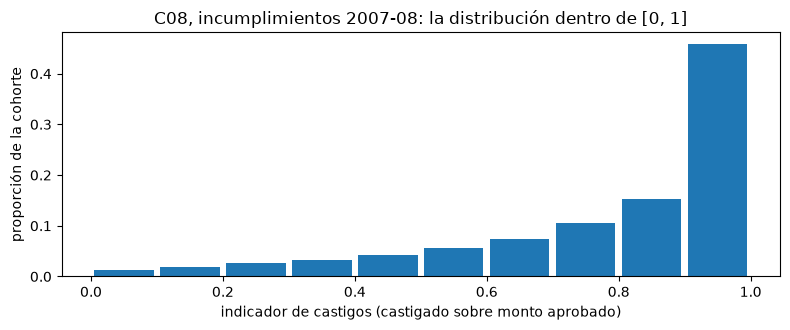

In [10]:
# Dibujar la distribución dentro de [0, 1] y contar las recuperaciones abiertas fuera del entrenamiento
bins = dist["bins"]
centres = [(x["lower"] + x["upper"]) / 2 for x in bins]
print("incumplimientos de entrenamiento:", f"{out['training']['n_defaults']:,}")
print("recuperaciones abiertas excluidas y contadas:", f"{out['training']['n_open_workouts_excluded']:,}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(centres, [x["share"] for x in bins], width=0.09, color="tab:blue")
ax.set_xlabel("indicador de castigos (castigado sobre monto aprobado)")
ax.set_ylabel("proporción de la cohorte")
ax.set_title("C08, incumplimientos 2007-08: la distribución dentro de [0, 1]")
fig.tight_layout()
plt.show()

Lectura de las barras: la masa no se reparte parejo sino que se inclina a la derecha, con las barras más altas en los últimos tramos, así que la mayoría de los incumplimientos de pequeñas empresas de 2007-08 se castigó por la mayor parte del monto aprobado. Junto con el 12,66% de préstamos exactamente en 1 y el 2,34% sobre 1, que quedan fuera de los diez tramos, esto es la media de la cohorte de 0,8178 en forma de imagen. Lo que la figura no puede decir es cuánto recuperó después el prestamista, porque el archivo público termina en el castigo; esa es la declaración de sesgo a la baja que hace el artefacto, y por eso importan las 7.388 recuperaciones abiertas excluidas del entrenamiento: son los casos lentos que los cerrados no representan.

La función `lgd_distribution(lgd, edges)` del motor construye el mismo tipo de tabla a partir de valores por préstamo: los conteos por tramo dentro de [0, 1], los valores fuera contados aparte y las masas exactas en 0 y 1. El artefacto guarda su resultado, no los valores por préstamo (el archivo SBA es un conjunto de terceros que no se versiona), así que la última celda corre la función con las cuatro LGD inventadas del paso 1 y los bordes de tramo del propio artefacto, para mostrar qué devuelve y cómo deja fuera de los tramos los valores fuera de [0, 1].

In [11]:
# Correr lgd_distribution con las cuatro LGD inventadas y los bordes de tramo del artefacto
edges = np.array([bins[0]["lower"]] + [x["upper"] for x in bins])
table = workout.lgd_distribution(lgd, edges)
print("bordes:", edges)
print("conteos por tramo:", table.counts)
print(f"n={table.n} | bajo 0={table.n_below_zero} | sobre 1={table.n_above_one}")
print(f"masa en 0={table.mass_zero} | masa en 1={table.mass_one}")

bordes: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
conteos por tramo: [0 0 1 0 1 0 0 0 0 0]
n=4 | bajo 0=1 | sobre 1=1
masa en 0=0 | masa en 1=0


## Resultados

**Respuesta:** Descontadas a 8%, las recuperaciones del préstamo inventado A valen 78.417,64 frente a una exposición de 100.000, así que pierde 0,2158 de ella, y la misma aritmética da -0,2307 para el préstamo D, recuperado en exceso, y 1,0753 para el préstamo C, cargado de costos. El indicador de castigos de C08 es otro objeto: sin flujos que descontar, los 25.299 incumplimientos de 2007-08 tienen una media por préstamo de 0,8178 y una razón agrupada de 0,6478, de modo que mide lo castigado y no la pérdida tras las recuperaciones, y no puede hacerse pasar por una LGD de recuperación.

- **La LGD de recuperación es un valor presente.** El préstamo A tiene una LGD de 0,2158: las recuperaciones, netas de costos y descontadas a 8%, valen 78.417,64 frente a una exposición de 100.000 (el cálculo a mano y `workout_lgd` coinciden). En la tabla del paso 2 una tasa más alta sube la LGD de los préstamos A, B y D, y baja la del préstamo C, cuyos flujos netos son negativos, de modo que el descuento reduce lo que paga.
- **Fuera de [0, 1] es información.** El préstamo C, cargado de costos, está en 1,0753 y el D, sobrerrecuperado, en -0,2307; recortarlos mueve la media de los cuatro de 0,3736 a 0,4125.
- **Las recuperaciones abiertas deben tratarse, y el tratamiento es un número.** Excluir las cuatro recuperaciones abiertas da una LGD media de 0,4917; proyectarlas da 0,6250. Esa brecha es el sesgo a la baja del que advierte la investigación, y `resolve_incomplete` devuelve los conteos para que la elección sea visible. Las cuatro recuperaciones son inventadas, así que el tamaño de la brecha no dice nada de una cartera real.
- **C08 es un indicador sustituto, no una LGD de recuperación.** No hay flujos de recuperación, nada se descuenta, y el artefacto declara la dirección de su sesgo. Para la cohorte 2007-08 (25.299 incumplimientos) la media del indicador sustituto por préstamo es 0,8178 mientras que la razón agrupada del total castigado sobre el total aprobado es 0,6478. 3.204 préstamos (12,66%) están exactamente en 1 y 593 (2,34%) están sobre 1, conservados y marcados; ninguno está bajo 0.

Lo que el notebook no hace: no estima una LGD de recuperación para una cartera real, porque los datos versionados no tienen flujos. Los cuatro préstamos de los pasos 1 a 4 son inventados para mostrar la aritmética, y sus números no dicen nada de ningún prestamista. El notebook siguiente pasa a la otra mitad de la exposición, la exposición al incumplimiento y el factor de conversión de crédito.

## Resumen

- La LGD realizada es uno menos las recuperaciones netas descontadas sobre la EAD; `workout_lgd` la calcula para muchos préstamos a la vez y rechaza entradas inconsistentes.
- La tasa de descuento es una convención declarada (`eba_discount_rate` es la suma al estilo europeo de una tasa interbancaria y un recargo), y una tasa más alta sube la LGD de un préstamo cuyos flujos netos son positivos.
- Una LGD realizada fuera de [0, 1] se conserva y se marca con `range_flag`, nunca se recorta.
- Las recuperaciones abiertas sesgan la LGD a la baja si simplemente se omiten; `resolve_incomplete` hace explícito el tratamiento y `closed_before` enuncia la regla del conjunto de entrenamiento.
- La LGD versionada de C08 es un indicador sustituto de castigos sobre datos públicos de pequeñas empresas: sin flujos, sin descuento, con una dirección de sesgo declarada, y con valores sobre 1 conservados y marcados.

**Qué probar a continuación.** Cambia la tasa del paso 1 y los costos del préstamo C y mira cómo se mueven las LGD; luego sigue con el notebook 02, que hace lo mismo para la exposición al incumplimiento.

## Referencias

- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas: cálculo de activos ponderados por riesgo de crédito; los pisos de LGD y el tratamiento de la LGD en el enfoque avanzado). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424), los pisos de LGD del enfoque avanzado. https://www.bis.org/bcbs/publ/d424.htm
- La documentación del propio motor del módulo: `riskvalidation.lgd_ead.workout` (la fórmula, las marcas de rango y el tratamiento de recuperaciones incompletas, leídos de sus docstrings en la versión 0.8.1).
- Este repositorio: `docs/design/SDD.md` (caso C08, el gemelo de castigos SBA 7(a)) y `data/derived/C08/dc-2007-08.json` (`outputs.lgd_proxy`).